# Tugas Praktikum: Sequential Pattern Mining pada Online Retail

**Dataset:** Online Retail (UCI) · **Algoritma:** PrefixSpan (untuk sequence berisi itemset) · **Min. support awal:** 0,01 (relatif terhadap jumlah pelanggan)

Alur: (1) import data → (2) eksplorasi & pembersihan → (3) penyusunan sequence per pelanggan → (4) PrefixSpan → (5) evaluasi pola (support, confidence) → (6) kesimpulan.

In [1]:
import warnings, time, math, json, os
warnings.filterwarnings('ignore')
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})
OUT = 'out'; os.makedirs(OUT, exist_ok=True)
BLUE, ORANGE, GREEN, GREY = '#2F5D8A', '#E0803A', '#4C9A6A', '#9AA5B1'

## 1. Unduh dan Import Dataset

In [2]:
df = pd.read_excel('Online_Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print('Shape (baris, kolom):', df.shape)

Shape (baris, kolom): (541909, 8)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


Dataset berisi 8 atribut: `InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`.
Untuk analisis pola berurutan, kolom yang relevan adalah **`CustomerID`** (pemilik sequence), **`InvoiceNo`** (pembentuk itemset), **`InvoiceDate`** (urutan waktu), dan **`Description`** (item). `Quantity` dipakai untuk menyaring data tidak valid.

## 2. Eksplorasi dan Pembersihan Data

In [5]:
print('Nilai kosong per kolom:'); print(df.isna().sum().to_string())
print('\nRingkasan Quantity:'); print(df['Quantity'].describe().round(2).to_string())
print('\nInvoice dibatalkan (awalan C):', df['InvoiceNo'].astype(str).str.startswith('C').sum(), 'baris')
print('Periode data:', df['InvoiceDate'].min(), 's/d', df['InvoiceDate'].max())

Nilai kosong per kolom:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0

Ringkasan Quantity:
count    541909.00
mean          9.55
std         218.08
min      -80995.00
25%           1.00
50%           3.00
75%          10.00
max       80995.00

Invoice dibatalkan (awalan C): 9288 baris


Periode data: 2010-12-01 08:26:00 s/d 2011-12-09 12:50:00


In [6]:
def stat(d, label):
    return {'Tahap': label, 'Baris': len(d), 'Invoice': d['InvoiceNo'].nunique(), 'Pelanggan': d['CustomerID'].nunique()}

steps = [stat(df, 'Data awal')]
d = df.dropna(subset=['Description']);                         steps.append(stat(d, 'Hapus Description kosong'))
d = d[~d['InvoiceNo'].astype(str).str.startswith('C')];        steps.append(stat(d, 'Hapus invoice batal ("C")'))
d = d[d['Quantity'] > 0];                                      steps.append(stat(d, 'Hapus Quantity <= 0'))
d = d.dropna(subset=['CustomerID']);                           steps.append(stat(d, 'Hapus CustomerID kosong'))

# Normalisasi teks Description (spasi berlebih / huruf besar-kecil) agar item yang sama tidak terpecah
d = d.assign(Description=d['Description'].str.strip().str.upper())
clean = d.copy()

tbl_clean = pd.DataFrame(steps)
tbl_clean.to_csv(f'{OUT}/cleaning_steps.csv', index=False)
tbl_clean

,Tahap,Baris,Invoice,Pelanggan
0,Data awal,541909,25900,4372
1,Hapus Description kosong,540455,24446,4372
2,"Hapus invoice batal (""C"")",531167,20610,4339
3,Hapus Quantity <= 0,530693,20136,4339
4,Hapus CustomerID kosong,397924,18536,4339


In [7]:
b, a = tbl_clean.iloc[0], tbl_clean.iloc[-1]
ringkas = pd.DataFrame({'Sebelum': [b.Baris, b.Invoice, b.Pelanggan], 'Sesudah': [a.Baris, a.Invoice, a.Pelanggan]},
                       index=['Jumlah baris', 'Jumlah invoice', 'Jumlah pelanggan'])
ringkas['Berkurang'] = ringkas['Sebelum'] - ringkas['Sesudah']
ringkas['Berkurang (%)'] = (ringkas['Berkurang'] / ringkas['Sebelum'] * 100).round(1)
ringkas

,Sebelum,Sesudah,Berkurang,Berkurang (%)
Jumlah baris,541909,397924,143985,26.6
Jumlah invoice,25900,18536,7364,28.4
Jumlah pelanggan,4372,4339,33,0.8


Pembersihan menyisakan **397.924 baris (26,6% baris dibuang)**, **18.536 invoice**, dan **4.339 pelanggan**. Pengurangan terbesar berasal dari `CustomerID` kosong (132.769 baris), yaitu transaksi tanpa identitas pelanggan yang memang tidak dapat disusun menjadi sequence. Invoice batal (awalan "C") menghapus 3.836 invoice, dan 33 pelanggan hilang karena seluruh transaksinya adalah pembatalan.

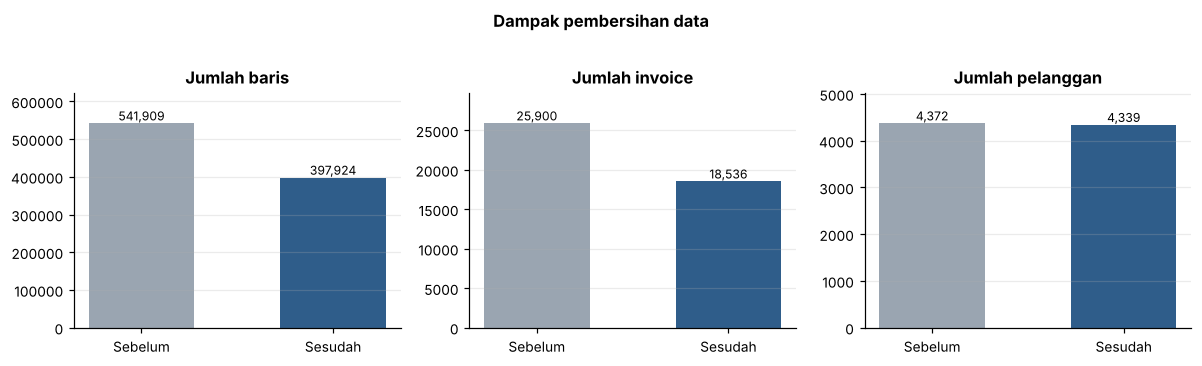

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for i, (col, ttl) in enumerate([('Baris', 'Jumlah baris'), ('Invoice', 'Jumlah invoice'), ('Pelanggan', 'Jumlah pelanggan')]):
    vals = [b[col], a[col]]
    bars = ax[i].bar(['Sebelum', 'Sesudah'], vals, color=[GREY, BLUE], width=.55)
    ax[i].set_title(ttl, fontweight='bold'); ax[i].grid(axis='x', visible=False)
    for r, v in zip(bars, vals): ax[i].text(r.get_x()+r.get_width()/2, v, f'{int(v):,}', ha='center', va='bottom', fontsize=8)
    ax[i].set_ylim(0, max(vals)*1.15)
plt.suptitle('Dampak pembersihan data', y=1.02, fontweight='bold'); plt.tight_layout()
plt.savefig(f'{OUT}/fig1_cleaning.png', bbox_inches='tight'); plt.show()

Produk unik (Description): 3866

Invoice per pelanggan:
 count    4339.00
mean        4.27
std         7.71
min         1.00
25%         1.00
50%         2.00
75%         5.00
max       210.00

Produk unik per invoice:
 count    18536.00
mean        20.92
std         23.80
min          1.00
25%          6.00
50%         15.00
75%         27.00
max        541.00

Pelanggan dengan >= 2 invoice: 2845 (65.6%)


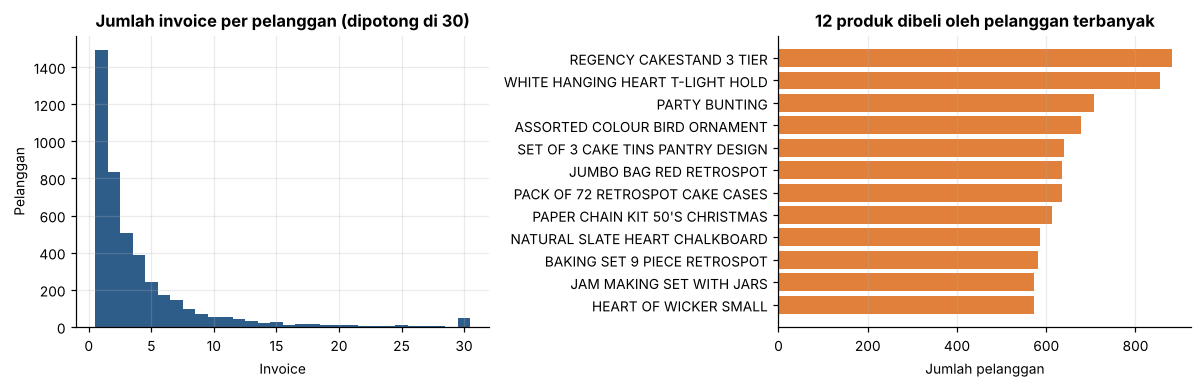

In [9]:
inv_per_cust = clean.groupby('CustomerID')['InvoiceNo'].nunique()
item_per_inv = clean.groupby('InvoiceNo')['Description'].nunique()
cust_per_item = clean.groupby('Description')['CustomerID'].nunique().sort_values(ascending=False)
print('Produk unik (Description):', clean['Description'].nunique())
print('\nInvoice per pelanggan:\n', inv_per_cust.describe().round(2).to_string())
print('\nProduk unik per invoice:\n', item_per_inv.describe().round(2).to_string())
print('\nPelanggan dengan >= 2 invoice:', (inv_per_cust >= 2).sum(), f'({(inv_per_cust>=2).mean():.1%})')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(inv_per_cust.clip(upper=30), bins=np.arange(1, 32)-.5, color=BLUE)
ax[0].set_title('Jumlah invoice per pelanggan (dipotong di 30)', fontweight='bold'); ax[0].set_xlabel('Invoice'); ax[0].set_ylabel('Pelanggan')
top = cust_per_item.head(12)[::-1]
ax[1].barh([s[:32] for s in top.index], top.values, color=ORANGE)
ax[1].set_title('12 produk dibeli oleh pelanggan terbanyak', fontweight='bold'); ax[1].set_xlabel('Jumlah pelanggan')
ax[1].grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig(f'{OUT}/fig2_eksplorasi.png', bbox_inches='tight'); plt.show()

**Catatan:** sequence disusun *per pelanggan*, sehingga pelanggan yang hanya punya satu invoice hanya menghasilkan satu itemset dan tidak dapat memunculkan pola lintas waktu. Mereka tetap dihitung pada penyebut support (jumlah seluruh pelanggan setelah pembersihan), sesuai ketentuan tugas.

## 3. Persiapan Data untuk Sequential Pattern Mining

In [10]:
# Urutkan per pelanggan dan waktu, lalu satu invoice = satu itemset (item unik, diurutkan alfabet)
clean = clean.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo'])
invoices = (clean.groupby(['CustomerID', 'InvoiceNo'], sort=False)
                 .agg(InvoiceDate=('InvoiceDate', 'min'), Items=('Description', lambda s: sorted(set(s))))
                 .reset_index()
                 .sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo']))

# Satu sequence per pelanggan = list of list (setiap list dalam = itemset satu invoice)
seq_df = invoices.groupby('CustomerID')['Items'].apply(list)
sequences = seq_df.tolist()
N = len(sequences)
print('Jumlah sequence (pelanggan):', N)
print('Contoh sequence pelanggan', seq_df.index[1], f'({len(sequences[1])} itemset):')
for i, s in enumerate(sequences[1][:3], 1): print(f'  itemset {i}:', s[:4], '...' if len(s) > 4 else '')

Jumlah sequence (pelanggan): 4339
Contoh sequence pelanggan 12347.0 (7 itemset):
  itemset 1: ['3D DOG PICTURE PLAYING CARDS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'ALARM CLOCK BAKELIKE CHOCOLATE', 'ALARM CLOCK BAKELIKE GREEN'] ...
  itemset 2: ['3D DOG PICTURE PLAYING CARDS', '60 TEATIME FAIRY CAKE CASES', '72 SWEETHEART FAIRY CAKE CASES', 'AIRLINE BAG VINTAGE JET SET BROWN'] ...
  itemset 3: ['3D SHEET OF CAT STICKERS', '3D SHEET OF DOG STICKERS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'AIRLINE BAG VINTAGE JET SET RED'] ...


In [11]:
lens = pd.Series([len(s) for s in sequences])
size = pd.Series([len(e) for s in sequences for e in s])
print(f'Itemset per sequence  : rata-rata {lens.mean():.2f}, median {lens.median():.0f}, maks {lens.max()}')
print(f'Item per itemset      : rata-rata {size.mean():.2f}, median {size.median():.0f}, maks {size.max()}')

Itemset per sequence  : rata-rata 4.27, median 2, maks 210
Item per itemset      : rata-rata 20.92, median 15, maks 541


## 4. Penerapan Algoritma — PrefixSpan

Pustaka `prefixspan` di PyPI hanya menerima sequence berisi **item tunggal**, padahal di sini satu invoice dapat berisi banyak produk sekaligus (itemset). Karena itu PrefixSpan diimplementasikan langsung di bawah ini dengan dua jenis ekstensi pola:

* **S-extension** (sequence): item baru ditambahkan sebagai itemset baru, yaitu dibeli pada invoice *berikutnya*.
* **I-extension** (itemset): item baru ditambahkan ke itemset terakhir, yaitu dibeli pada invoice *yang sama*.

Support sebuah pola = jumlah pelanggan yang sequence-nya memuat pola tersebut (setiap pelanggan dihitung sekali).

In [12]:
def prefixspan(seqs, minsup, maxlen=99):
    """PrefixSpan untuk sequence of itemsets.
    seqs   : list of list of set (itemset per invoice)
    minsup : support minimum dalam jumlah pelanggan
    maxlen : batas jumlah total item dalam pola (untuk eksperimen cepat)
    return : dict {pola (tuple of tuple): support absolut}"""
    hasil = {}
    def mine(pola, proj):
        if sum(len(e) for e in pola) >= maxlen: return
        s_cnt, i_cnt = defaultdict(int), defaultdict(int)
        akhir = set(pola[-1]) if pola else None
        for sid, ei in proj:
            s = seqs[sid]
            seen = set()
            for e in s[ei+1:]: seen |= e
            for it in seen: s_cnt[it] += 1
            if pola:
                seen = set()
                for e in s[ei:]:
                    if akhir <= e: seen |= {x for x in e if x > pola[-1][-1]}
                for it in seen: i_cnt[it] += 1
        for it, c in s_cnt.items():                      # S-extension
            if c >= minsup:
                p = pola + [(it,)]; hasil[tuple(p)] = c
                np_ = []
                for sid, ei in proj:
                    s = seqs[sid]
                    for j in range(ei+1, len(s)):
                        if it in s[j]: np_.append((sid, j)); break
                mine(p, np_)
        for it, c in i_cnt.items():                      # I-extension
            if c >= minsup:
                p = pola[:-1] + [pola[-1] + (it,)]; hasil[tuple(p)] = c
                baru = set(p[-1]); np_ = []
                for sid, ei in proj:
                    s = seqs[sid]
                    for j in range(ei, len(s)):
                        if baru <= s[j]: np_.append((sid, j)); break
                mine(p, np_)
    mine([], [(i, -1) for i in range(len(seqs))])
    return hasil

def jalankan(minsup_rel, maxlen=99):
    ms = math.ceil(minsup_rel * N)
    cnt = Counter()
    for q in sequences: cnt.update(set().union(*q))
    freq = {i for i, c in cnt.items() if c >= ms}            # buang item yang tidak mungkin frequent
    db = [[frozenset(e) & freq for e in q if frozenset(e) & freq] for q in sequences]
    db = [q for q in db if q]
    t = time.time(); res = prefixspan(db, ms, maxlen)
    return res, ms, len(freq), time.time() - t

**Validasi implementasi.** Hasil implementasi dibandingkan dengan pustaka `prefixspan` pada kasus yang sebanding, yaitu setiap item diperlakukan sebagai itemset berukuran satu (hanya S-extension), pada 1.000 pelanggan pertama.

In [13]:
from prefixspan import PrefixSpan
sub = [[it for e in s for it in e] for s in sequences[:1000]]          # urutan item datar
ref = {tuple(p): c for c, p in PrefixSpan(sub).frequent(40)}
mine_ = prefixspan([[frozenset([it]) for it in s] for s in sub], 40)
mine_ = {tuple(e[0] for e in p): c for p, c in mine_.items()}
print('Pola pustaka prefixspan :', len(ref)); print('Pola implementasi sendiri:', len(mine_))
print('Identik (pola & support):', ref == mine_)

Pola pustaka prefixspan : 1042
Pola implementasi sendiri: 1042
Identik (pola & support): True


### Pemilihan minimum support

Tugas meminta min. support 0,01 sebagai titik awal. Percobaan di bawah memperlihatkan bagaimana jumlah pola berubah menurut nilai support.

In [14]:
rows = []
for th, ml in [(0.01, 2), (0.015, 99), (0.02, 99), (0.03, 99), (0.05, 99)]:
    res, ms, nf, dur = jalankan(th, ml)
    rows.append({'min_support': th, 'min_support (pelanggan)': ms, 'Item frequent': nf, 'Jumlah pola': len(res),
                 'Waktu (dtk)': round(dur, 1),
                 'Catatan': 'dibatasi maks 2 item (batas bawah)' if ml < 99 else 'lengkap'})
    print(rows[-1])
tbl_th = pd.DataFrame(rows); tbl_th.to_csv(f'{OUT}/threshold.csv', index=False); tbl_th

{'min_support': 0.01, 'min_support (pelanggan)': 44, 'Item frequent': 1763, 'Jumlah pola': 22851, 'Waktu (dtk)': 13.4, 'Catatan': 'dibatasi maks 2 item (batas bawah)'}


{'min_support': 0.015, 'min_support (pelanggan)': 66, 'Item frequent': 1350, 'Jumlah pola': 16700, 'Waktu (dtk)': 57.9, 'Catatan': 'lengkap'}


{'min_support': 0.02, 'min_support (pelanggan)': 87, 'Item frequent': 1046, 'Jumlah pola': 5176, 'Waktu (dtk)': 22.1, 'Catatan': 'lengkap'}


{'min_support': 0.03, 'min_support (pelanggan)': 131, 'Item frequent': 657, 'Jumlah pola': 1259, 'Waktu (dtk)': 6.9, 'Catatan': 'lengkap'}


{'min_support': 0.05, 'min_support (pelanggan)': 217, 'Item frequent': 265, 'Jumlah pola': 306, 'Waktu (dtk)': 1.7, 'Catatan': 'lengkap'}


,min_support,min_support (pelanggan),Item frequent,Jumlah pola,Waktu (dtk),Catatan
0,0.010,44,1763,22851,13.4,dibatasi maks 2 item (batas bawah)
1,0.015,66,1350,16700,57.9,lengkap
2,0.020,87,1046,5176,22.1,lengkap
3,0.030,131,657,1259,6.9,lengkap
4,0.050,217,265,306,1.7,lengkap


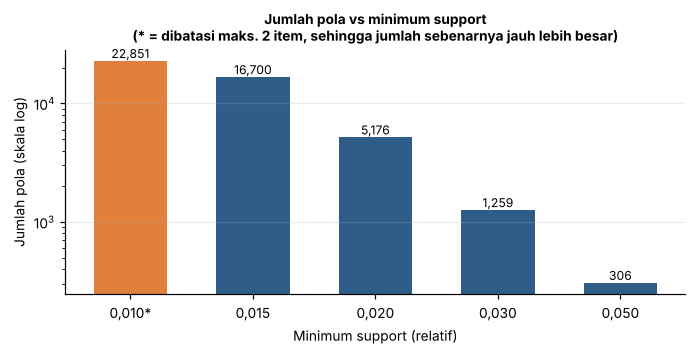

In [15]:
fig, ax = plt.subplots(figsize=(6.4, 3.3))
lbl = [f"{r['min_support']:.3f}".replace('.', ',') + ('*' if r['Catatan'] != 'lengkap' else '') for _, r in tbl_th.iterrows()]
cols = [ORANGE if '*' in l else BLUE for l in lbl]
bars = ax.bar(lbl, tbl_th['Jumlah pola'], color=cols, width=.6)
for r, v in zip(bars, tbl_th['Jumlah pola']): ax.text(r.get_x()+r.get_width()/2, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
ax.set_yscale('log'); ax.set_xlabel('Minimum support (relatif)'); ax.set_ylabel('Jumlah pola (skala log)')
ax.set_title('Jumlah pola vs minimum support\n(* = dibatasi maks. 2 item, sehingga jumlah sebenarnya jauh lebih besar)', fontsize=9, fontweight='bold')
ax.grid(axis='x', visible=False); plt.tight_layout(); plt.savefig(f'{OUT}/fig3_threshold.png', bbox_inches='tight'); plt.show()

Pada **0,01** (44 pelanggan) sudah terdapat >22.800 pola hanya untuk pola sepanjang paling banyak 2 item; dengan batas 3 item jumlahnya menjadi >59.000 dan eksekusi penuh tidak selesai dalam waktu wajar. Pola sebanyak itu terlalu banyak untuk dievaluasi, dan sebagian besar kombinasi hanya didukung oleh puluhan pelanggan sehingga rentan kebetulan. Pada **0,05** hanya tersisa 306 pola (hanya sampai 3 item), terlalu sedikit untuk menggambarkan variasi perilaku belanja.

**Nilai yang dipakai: 0,02** (87 dari 4.339 pelanggan). Hasilnya cukup beragam (sekitar 5 ribu pola, hingga 6 item), tetap bisa dihitung penuh dan dievaluasi, serta setiap pola didukung minimal 87 pelanggan.

In [16]:
MIN_SUP = 0.02
patterns, ms_abs, n_freq, dur = jalankan(MIN_SUP)
print(f'min_support = {MIN_SUP} -> {ms_abs} pelanggan | item frequent: {n_freq} | pola: {len(patterns):,} | waktu: {dur:.1f} dtk')

min_support = 0.02 -> 87 pelanggan | item frequent: 1046 | pola: 5,176 | waktu: 22.5 dtk


## 5. Evaluasi Pola Berurutan

**Definisi ukuran**

* **Support** = (jumlah pelanggan yang memuat pola) / (jumlah seluruh pelanggan).
* **Confidence** = support(pola lengkap) / support(antecedent), dengan antecedent adalah pola tanpa item terakhir. Artinya: di antara pelanggan yang sudah mengikuti bagian awal pola, berapa persen yang kemudian melengkapi pola itu.
* **Lift** = confidence / support(item terakhir). Lift > 1 berarti pola tersebut lebih mungkin terjadi dibanding kebetulan.

Pola dengan **satu itemset** (misalnya `{A, B}`) adalah *co-purchase* dalam satu invoice, bukan urutan antar waktu. Pola **berurutan** sejati memuat minimal dua itemset (`A → B`: A dibeli lebih dulu, B di invoice berikutnya).

In [17]:
def fmt(p):
    return ' → '.join(e[0] if len(e) == 1 else '{' + ', '.join(e) + '}' for e in p)

def n_items(p): return sum(len(e) for e in p)

def antecedent(p):
    if len(p[-1]) == 1: return p[:-1]
    return p[:-1] + (p[-1][:-1],)

def consequent_item(p): return ((p[-1][-1],),)

rows = []
for p, c in patterns.items():
    if n_items(p) < 2: continue
    a = antecedent(p)
    conf = c / patterns[a]
    lift = conf / (patterns[consequent_item(p)] / N)
    rows.append({'Pola': fmt(p), 'Jenis': 'Berurutan (>=2 invoice)' if len(p) > 1 else 'Co-purchase (1 invoice)',
                 'Panjang (item)': n_items(p), 'Itemset': len(p), 'Pelanggan': c, 'Support': c / N,
                 'Confidence': conf, 'Lift': lift, 'Antecedent': fmt(a), 'Konsekuen': p[-1][-1], '_p': p})
pat = pd.DataFrame(rows).sort_values(['Support', 'Confidence'], ascending=False).reset_index(drop=True)
seq_pat = pat[pat['Itemset'] >= 2].reset_index(drop=True)
print(f'Total pola (>=2 item): {len(pat):,} | Berurutan sejati: {len(seq_pat):,} | Co-purchase satu invoice: {(pat.Itemset==1).sum():,}')
pat.drop(columns='_p').to_csv(f'{OUT}/semua_pola.csv', index=False)

Total pola (>=2 item): 4,130 | Berurutan sejati: 2,976 | Co-purchase satu invoice: 1,154


In [18]:
tampil = ['Pola', 'Pelanggan', 'Support', 'Confidence', 'Lift']
fmtd = {'Support': '{:.4f}', 'Confidence': '{:.3f}', 'Lift': '{:.2f}'}
print('20 pola berurutan dengan support tertinggi'); seq_pat[tampil].head(20).style.format(fmtd)

20 pola berurutan dengan support tertinggi


,Pola,Pelanggan,Support,Confidence,Lift
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,405,0.0933,0.473,2.40
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,330,0.0761,0.375,1.84
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,312,0.0719,0.491,3.36
3,ASSORTED COLOUR BIRD ORNAMENT → ASSORTED COLOUR BIRD ORNAMENT,291,0.0671,0.429,2.75
4,PARTY BUNTING → PARTY BUNTING,280,0.0645,0.395,2.42
5,LUNCH BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,276,0.0636,0.519,4.23
6,LUNCH BAG BLACK SKULL. → LUNCH BAG BLACK SKULL.,229,0.0528,0.500,4.74
7,SET OF 3 CAKE TINS PANTRY DESIGN → SET OF 3 CAKE TINS PANTRY DESIGN,225,0.0519,0.352,2.38
8,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,222,0.0512,0.548,2.78
9,LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.,212,0.0489,0.398,3.78


In [19]:
print('15 pola berurutan antar produk BERBEDA dengan support tertinggi (selain pembelian ulang)')
beda = seq_pat[seq_pat['_p'].apply(lambda p: len({i for e in p for i in e}) > 1)]
beda[tampil].head(15).style.format(fmtd)

15 pola berurutan antar produk BERBEDA dengan support tertinggi (selain pembelian ulang)


,Pola,Pelanggan,Support,Confidence,Lift
9,LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.,212,0.0489,0.398,3.78
10,LUNCH BAG CARS BLUE → LUNCH BAG RED RETROSPOT,209,0.0482,0.436,3.56
11,LUNCH BAG BLACK SKULL. → LUNCH BAG RED RETROSPOT,208,0.0479,0.454,3.70
12,LUNCH BAG RED RETROSPOT → LUNCH BAG SPACEBOY DESIGN,207,0.0477,0.389,3.45
14,REGENCY CAKESTAND 3 TIER → SET OF 3 REGENCY CAKE TINS,206,0.0475,0.234,2.15
16,LUNCH BAG RED RETROSPOT → LUNCH BAG SUKI DESIGN,203,0.0468,0.382,4.15
17,LUNCH BAG PINK POLKADOT → LUNCH BAG RED RETROSPOT,201,0.0463,0.453,3.69
19,JUMBO BAG RED RETROSPOT → JUMBO BAG VINTAGE DOILY,201,0.0463,0.317,3.78
20,JUMBO BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,200,0.0461,0.315,2.57
21,LUNCH BAG SPACEBOY DESIGN → LUNCH BAG RED RETROSPOT,198,0.0456,0.404,3.30


In [20]:
print('10 pola co-purchase (satu invoice) dengan support tertinggi')
pat[pat.Itemset == 1][tampil].head(10).style.format(fmtd)

10 pola co-purchase (satu invoice) dengan support tertinggi


,Pola,Pelanggan,Support,Confidence,Lift
2,"{PAPER CHAIN KIT 50'S CHRISTMAS, PAPER CHAIN KIT VINTAGE CHRISTMAS}",313,0.0721,0.511,4.71
4,"{GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER}",311,0.0717,0.804,8.24
6,"{GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY TEACUP AND SAUCER}",282,0.0650,0.729,9.91
8,"{HEART OF WICKER LARGE, HEART OF WICKER SMALL}",276,0.0636,0.569,4.31
10,"{RED HANGING HEART T-LIGHT HOLDER, WHITE HANGING HEART T-LIGHT HOLDER}",273,0.0629,0.709,3.59
11,"{REGENCY CAKESTAND 3 TIER, ROSES REGENCY TEACUP AND SAUCER}",266,0.0613,0.302,3.10
12,"{PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER}",256,0.0590,0.803,8.23
13,"{JUMBO BAG PINK POLKADOT, JUMBO BAG RED RETROSPOT}",255,0.0588,0.685,4.68
14,"{LUNCH BAG PINK POLKADOT, LUNCH BAG RED RETROSPOT}",255,0.0588,0.574,4.68
15,"{GARDENERS KNEELING PAD CUP OF TEA, GARDENERS KNEELING PAD KEEP CALM}",254,0.0585,0.724,7.75


### Tiga pola terbaik (support tertinggi)

In [21]:
top3 = seq_pat.head(3)
top3[['Pola', 'Pelanggan', 'Support', 'Confidence', 'Lift', 'Antecedent']].style.format(fmtd)

,Pola,Pelanggan,Support,Confidence,Lift,Antecedent
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,405,0.0933,0.473,2.40,WHITE HANGING HEART T-LIGHT HOLDER
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,330,0.0761,0.375,1.84,REGENCY CAKESTAND 3 TIER
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,312,0.0719,0.491,3.36,JUMBO BAG RED RETROSPOT


In [22]:
sup_item = {i: patterns[((i,),)] for i in [p[0][0] for p in patterns if len(p) == 1 and len(p[0]) == 1]}
top3_out = top3.drop(columns='_p').copy()
top3_out['Support item awal (pelanggan)'] = [sup_item[a.split(' → ')[0]] for a in top3_out['Antecedent']]
top3_out.to_csv(f'{OUT}/top3.csv', index=False); beda.head(15).drop(columns='_p').to_csv(f'{OUT}/top_beda.csv', index=False)
seq_pat.head(20).drop(columns='_p').to_csv(f'{OUT}/top20_seq.csv', index=False)
pat[pat.Itemset == 1].head(10).drop(columns='_p').to_csv(f'{OUT}/top_cop.csv', index=False)
top3_out[['Pola', 'Pelanggan', 'Support', 'Confidence', 'Lift', 'Support item awal (pelanggan)']]

,Pola,Pelanggan,Support,Confidence,Lift,Support item awal (pelanggan)
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HAN...,405,0.093339,0.473131,2.398265,856
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3...,330,0.076054,0.374574,1.844811,881
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,312,0.071906,0.491339,3.357351,635


### Interpretasi tiga pola terbaik

Ketiga pola terbaik berbentuk **pembelian ulang produk yang sama pada invoice yang lebih belakang** (`A → A`). Semuanya memiliki lift jauh di atas 1, sehingga ini perilaku yang nyata, bukan kebetulan karena produknya populer.

| # | Pola | Support | Confidence | Lift |
|---|------|---------|------------|------|
| 1 | WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER | 0,093 (405 pelanggan) | 0,473 | 2,40 |
| 2 | REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER | 0,076 (330 pelanggan) | 0,375 | 1,85 |
| 3 | JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT | 0,072 (312 pelanggan) | 0,491 | 3,36 |

1. **White Hanging Heart T-Light Holder.** Sekitar 9,3% seluruh pelanggan membeli produk ini lalu membelinya lagi di invoice berikutnya. Dari pelanggan yang pernah membelinya, 47,3% kembali membeli. Ini produk dekorasi/hadiah dengan perputaran tinggi, sehingga cocok untuk pengingat restock, diskon volume, dan stok pengaman.
2. **Regency Cakestand 3 Tier.** Confidence 37,5% menunjukkan pembeli yang kembali, kemungkinan untuk dijual lagi atau dibeli sebagai hadiah. Lift terendah dari ketiganya (1,85) karena produk ini sudah sangat populer, jadi sebagian kemunculannya memang terjadi secara alami. Produk ini juga muncul dalam pola lintas produk `REGENCY CAKESTAND 3 TIER → SET OF 3 REGENCY CAKE TINS` (support 0,047), sehingga bisa ditawarkan bersama koleksi Regency lainnya.
3. **Jumbo Bag Red Retrospot.** Confidence tertinggi (49,1%) dan lift 3,36: hampir separuh pembeli tas ini membelinya lagi. Tas adalah barang habis-pakai dan mudah dijual kembali, sehingga cocok untuk paket langganan, harga grosir bertingkat, dan promosi pembelian ulang.

Selain pembelian ulang, pola lintas produk dengan support tertinggi didominasi **varian dalam satu keluarga produk**, misalnya `LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL` (support 0,049; confidence 0,40; lift 3,78). Pelanggan cenderung melengkapi koleksi motif pada pembelian berikutnya, yang mendukung strategi rekomendasi varian dan bundling motif.

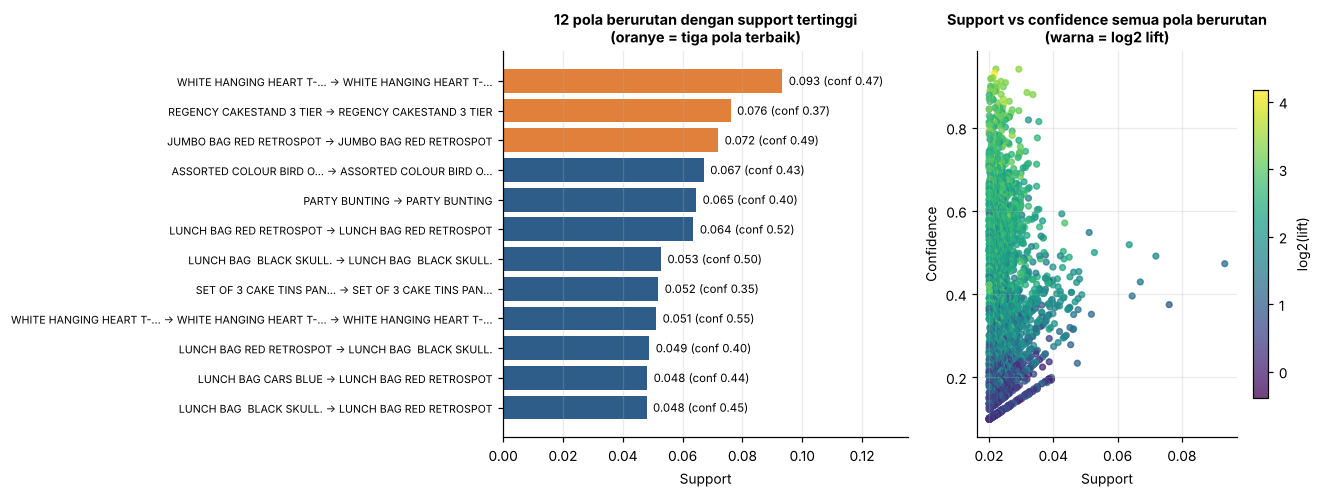

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
t = seq_pat.head(12)[::-1]
lab = [' → '.join((x if len(x) <= 24 else x[:22] + '…') for x in l.split(' → ')) for l in t['Pola']]
ypos = np.arange(len(t))
ax[0].barh(ypos, t['Support'], color=[ORANGE if i >= len(t)-3 else BLUE for i in range(len(t))])
ax[0].set_yticks(ypos); ax[0].set_yticklabels(lab)
for y, (s, c) in enumerate(zip(t['Support'], t['Confidence'])): ax[0].text(s, y, f'  {s:.3f} (conf {c:.2f})', va='center', fontsize=7.5)
ax[0].set_xlim(0, t['Support'].max()*1.45); ax[0].set_xlabel('Support')
ax[0].set_title('12 pola berurutan dengan support tertinggi\n(oranye = tiga pola terbaik)', fontweight='bold', fontsize=9.5); ax[0].grid(axis='y', visible=False)
ax[0].tick_params(axis='y', labelsize=7)
sc = ax[1].scatter(seq_pat['Support'], seq_pat['Confidence'], c=np.log2(seq_pat['Lift']), cmap='viridis', s=14, alpha=.75)
ax[1].set_xlabel('Support'); ax[1].set_ylabel('Confidence'); ax[1].set_title('Support vs confidence semua pola berurutan\n(warna = log2 lift)', fontweight='bold', fontsize=9.5)
plt.colorbar(sc, ax=ax[1], shrink=.8, label='log2(lift)')
plt.tight_layout(); plt.savefig(f'{OUT}/fig4_pola.png', bbox_inches='tight'); plt.show()

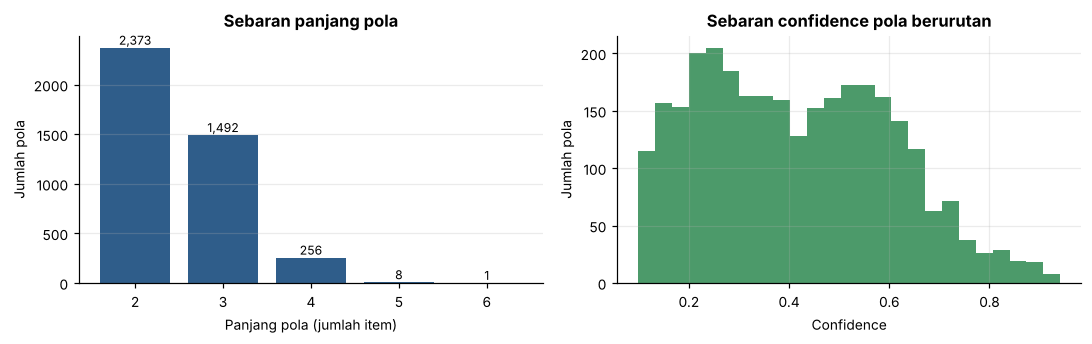

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
vc = pat['Panjang (item)'].value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color=BLUE); ax[0].set_xlabel('Panjang pola (jumlah item)'); ax[0].set_ylabel('Jumlah pola')
ax[0].set_title('Sebaran panjang pola', fontweight='bold'); ax[0].grid(axis='x', visible=False)
for x, v in zip(range(len(vc)), vc.values): ax[0].text(x, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
ax[1].hist(seq_pat['Confidence'], bins=25, color=GREEN); ax[1].set_xlabel('Confidence'); ax[1].set_ylabel('Jumlah pola')
ax[1].set_title('Sebaran confidence pola berurutan', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{OUT}/fig5_sebaran.png', bbox_inches='tight'); plt.show()

In [25]:
summary = {'N_pelanggan': int(N), 'min_sup': MIN_SUP, 'min_sup_abs': int(ms_abs), 'n_pola_total': int(len(patterns)),
           'n_pola_ge2': int(len(pat)), 'n_seq': int(len(seq_pat)), 'n_cop': int((pat.Itemset == 1).sum()),
           'max_len': int(pat['Panjang (item)'].max()), 'n_repeat_seq': int(len(seq_pat) - len(beda)),
           'pct_cust_ge2': float((inv_per_cust >= 2).mean()), 'n_prod': int(clean['Description'].nunique()),
           'med_inv': float(inv_per_cust.median()), 'mean_inv': float(inv_per_cust.mean()),
           'conf_median_seq': float(seq_pat['Confidence'].median()), 'lift_median_seq': float(seq_pat['Lift'].median()),
           'frac_lift_gt1': float((seq_pat['Lift'] > 1).mean()), 'n_beda': int(len(beda)),
           'period': [str(df['InvoiceDate'].min()), str(df['InvoiceDate'].max())],
           'n_ge2_cust': int((inv_per_cust >= 2).sum())}
json.dump(summary, open(f'{OUT}/summary.json', 'w'), indent=1, default=str); summary

{'N_pelanggan': 4339,
 'min_sup': 0.02,
 'min_sup_abs': 87,
 'n_pola_total': 5176,
 'n_pola_ge2': 4130,
 'n_seq': 2976,
 'n_cop': 1154,
 'max_len': 6,
 'n_repeat_seq': 165,
 'pct_cust_ge2': 0.6556810324959668,
 'n_prod': 3866,
 'med_inv': 2.0,
 'mean_inv': 4.271952062687255,
 'conf_median_seq': 0.4005305039787798,
 'lift_median_seq': 4.268037349312477,
 'frac_lift_gt1': 0.9895833333333334,
 'n_beda': 2811,
 'period': ['2010-12-01 08:26:00', '2011-12-09 12:50:00'],
 'n_ge2_cust': 2845}

## 6. Kesimpulan

1. **Data.** Setelah pembersihan tersisa 397.924 baris, 18.536 invoice, dan 4.339 pelanggan dengan 3.866 produk unik. Sebanyak 65,6% pelanggan (2.845) memiliki minimal dua invoice, sehingga cukup layak untuk analisis pola berurutan.
2. **Pemilihan parameter.** Min. support 0,01 menghasilkan terlalu banyak pola (lebih dari 22.800 hanya untuk pola sepanjang paling banyak 2 item, dan lebih dari 59.000 untuk maksimal 3 item), sedangkan 0,05 hanya menyisakan 306 pola. Nilai **0,02** (87 pelanggan) dipilih dan menghasilkan 5.176 pola, dengan panjang hingga 6 item. Dari jumlah itu, 4.130 pola memuat minimal 2 item, terdiri dari 2.976 pola berurutan antar-invoice dan 1.154 pola co-purchase dalam satu invoice.
3. **Kualitas pola.** Median confidence pola berurutan adalah 0,40 dan 99% di antaranya memiliki lift > 1 (median 4,27), sehingga pola yang ditemukan menggambarkan kecenderungan nyata dan bukan sekadar akibat popularitas produk.
4. **Pola utama.** Pola dengan support tertinggi adalah **pembelian ulang produk yang sama** (white hanging heart t-light holder, regency cakestand 3 tier, jumbo bag red retrospot), dengan support 7,2%–9,3% dan confidence 37,5%–49,1%. Pola lintas produk didominasi **varian dalam satu keluarga produk** (lunch bag berbagai motif) dan **produk pelengkap satu koleksi** (Regency cakestand → Regency cake tins).
5. **Implikasi bisnis.** Pembelian ulang yang kuat mendukung pengingat restock, diskon volume, dan perencanaan stok untuk produk-produk tersebut. Pola varian mendukung rekomendasi motif lain dan bundling koleksi pada pembelian berikutnya.
6. **Keterbatasan.** (a) Item didefinisikan dengan `Description`, sehingga varian warna/motif dihitung sebagai produk berbeda. (b) Data satu tahun (Des 2010–Des 2011) dan musiman, sehingga sebagian pola bisa dipengaruhi musim Natal. (c) Banyak pelanggan dataset ini adalah pedagang grosir, sehingga pembelian ulang bisa mencerminkan restock untuk dijual kembali, bukan konsumsi pribadi. (d) Tidak ada batasan jarak waktu antar-invoice, jadi `A → B` berarti B dibeli kapan pun setelah A.